# EO4FLOOD multi-mission water level along a river reach

DTU Space combines satellite altimetry into a water-level solution distributed along a river reach.
This Ebro example examines the station time series, its uncertainty, the full space–time grid,
longitudinal profiles and the geographic reach. The basin-wide Parquet asset is identified by its
EO4FLOOD STAC item.

One row is one `(chainage, time)` node of a virtual station and its associated reach. Grouping by
`VSReachID` and `VSgauge`, then pivoting chainage against time, reconstructs the space–time grid.

| Column | Meaning |
|---|---|
| `time` | Decimal year |
| `chainage` | Distance from the downstream end of the reach, increasing upstream, in metres |
| `wlgrid`, `wlsdgrid` | Water level and its 1σ uncertainty at a node and time, in metres |
| `wl`, `wlsd` | Station water-level solution and 1σ uncertainty, repeated across chainage |
| `lon`, `lat` | Geographic location of a node, repeated across time |
| `VSlon`, `VSlat`, `VSchainage`, `VSwidth`, `VSReachID`, `VSgauge`, `reachLength` | Station and reach metadata |

Chainage increases upstream in the delivered profiles: their time-mean elevation rises with
chainage. That direction is inferred from the profiles rather than explicitly recorded in the files.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASIN = "Ebro"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})

REACH = "21604100041"
GAUGE = "9027_AFD"
url = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/water_level_series/Ebro_multi-mission_water_level.parquet'
all_stations = pd.read_parquet(url)
display(all_stations[["VSReachID", "VSgauge", "VSlon", "VSlat"]].drop_duplicates())
station = all_stations.loc[(all_stations.VSReachID == REACH) & (all_stations.VSgauge == GAUGE)]
meta = station.iloc[0]
by_time = station.drop_duplicates("time").sort_values("time")
by_chainage = station.drop_duplicates("chainage").sort_values("chainage")
years = np.floor(by_time.time).astype(int)
starts = pd.to_datetime(years.astype(str), format="%Y")
ends = pd.to_datetime((years + 1).astype(str), format="%Y")
time = pd.DatetimeIndex(starts + (ends - starts) * (by_time.time - years))
chainage = by_chainage.chainage.to_numpy() / 1000
wl = by_time.wl.to_numpy()
sd = by_time.wlsd.to_numpy()
grid = station.pivot(index="chainage", columns="time", values="wlgrid").sort_index().sort_index(axis=1)
sdgrid = station.pivot(index="chainage", columns="time", values="wlsdgrid").sort_index().sort_index(axis=1)

,VSReachID,VSgauge,VSlon,VSlat
0,21604100041,9027_AFD,0.521063,40.814053
0,21604100041,6226800_GRDC,0.520660,40.813278
0,21604300241,9263_AFD,-0.474786,41.399982
0,21604500021,6226400_GRDC,-0.881060,41.658569
0,21604700171,6226300_GRDC,-1.694740,42.180080
0,21604700171,9002_AFD,-1.693396,42.181946


## Water level at the virtual station

The headline product is one height series for the point represented by the virtual station. The
±1σ band shares its axis with water level, while uncertainty has its own panel and scale below.
Spikes in uncertainty indicate that the solution was less tightly constrained; they can coincide
with reduced satellite coverage or a larger contribution from interpolation.

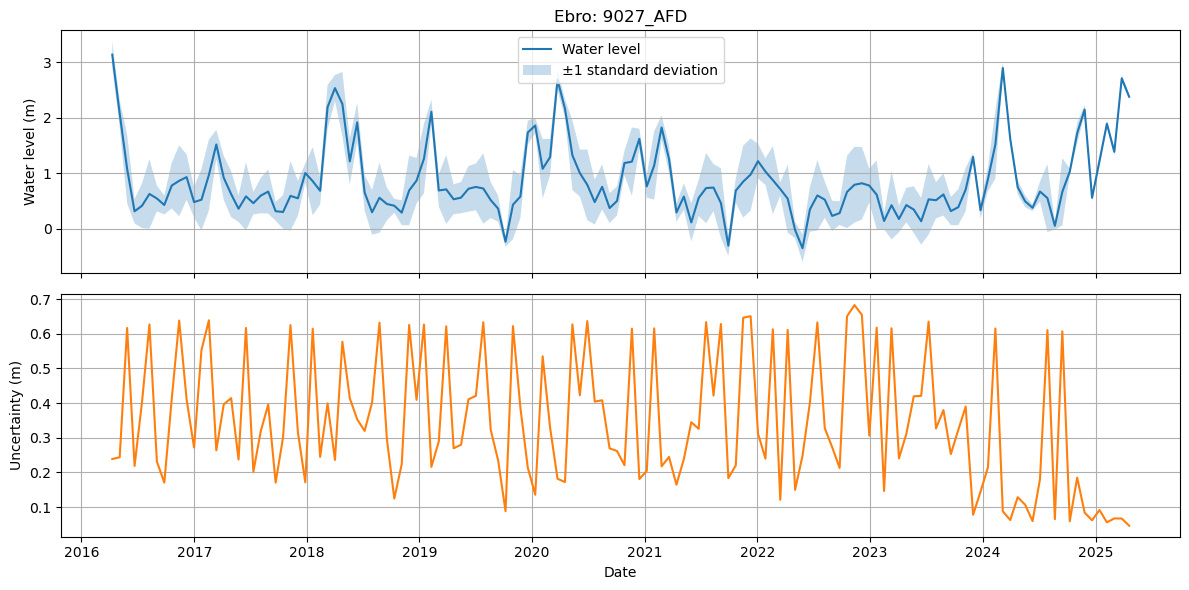

In [3]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
axes[0].plot(time, wl, label="Water level")
axes[0].fill_between(time, wl - sd, wl + sd, alpha=0.25, label="±1 standard deviation")
axes[0].set(ylabel="Water level (m)", title=f"{BASIN}: {GAUGE}")
axes[0].legend()
axes[1].plot(time, sd, color="tab:orange")
axes[1].set(ylabel="Uncertainty (m)", xlabel="Date")
fig.tight_layout()
plt.show()

## The space–time grid: Hovmöller diagrams

`wlgrid` is the solution along the reach at every time step. Space on the vertical axis and time
on the horizontal axis form a Hovmöller diagram: vertical features show changes affecting much of
the reach, including flood waves. The persistent gradient along chainage is the river's own slope;
the upstream nodes generally sit higher.

The companion `wlsdgrid` panel shows uncertainty on the same nodes. The water-level and uncertainty
panels describe the same reconstruction and are interpreted together. The virtual station's
chainage is marked by a dashed line.

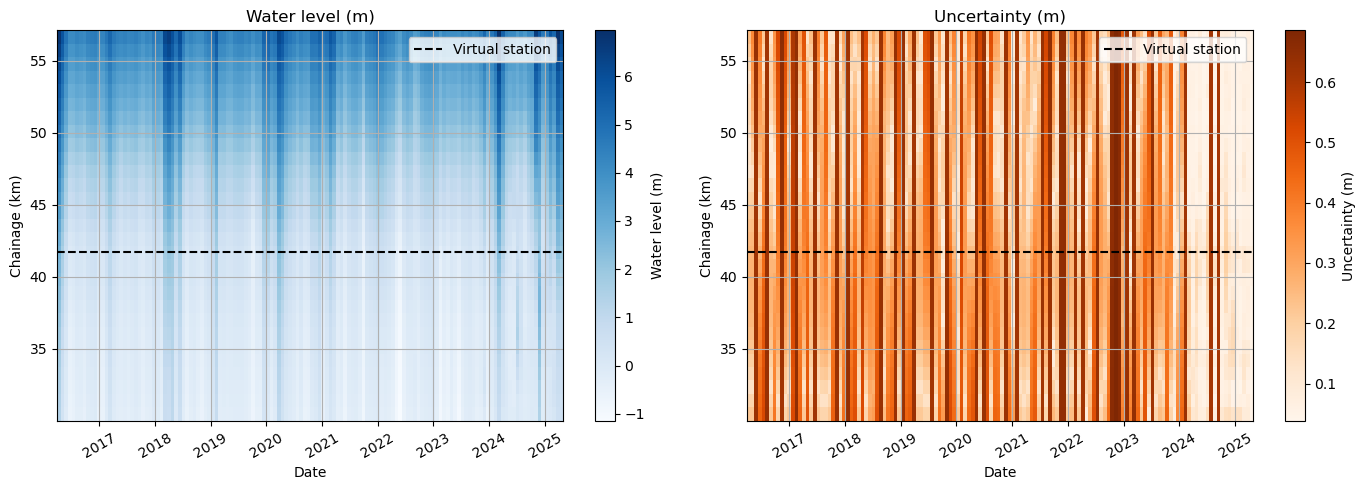

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for field, title, cmap, ax in zip([grid, sdgrid], ["Water level (m)", "Uncertainty (m)"],
                                  ["Blues", "Oranges"], axes):
    image = ax.pcolormesh(time, chainage, field.to_numpy(), shading="auto", cmap=cmap)
    fig.colorbar(image, ax=ax, label=title)
    ax.axhline(meta.VSchainage / 1000, color="black", linestyle="--", label="Virtual station")
    ax.set(title=title, xlabel="Date", ylabel="Chainage (km)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
fig.tight_layout()
plt.show()

## Longitudinal profiles

A cut through the grid at one time gives the water-surface profile: height along the river reach.
Three observation dates illustrate how both the profile and its uncertainty change. Elevation
increases toward larger chainage because this coordinate runs upstream from the downstream end.
The gradient relates to the water-surface-slope product distributed separately by EO4FLOOD.

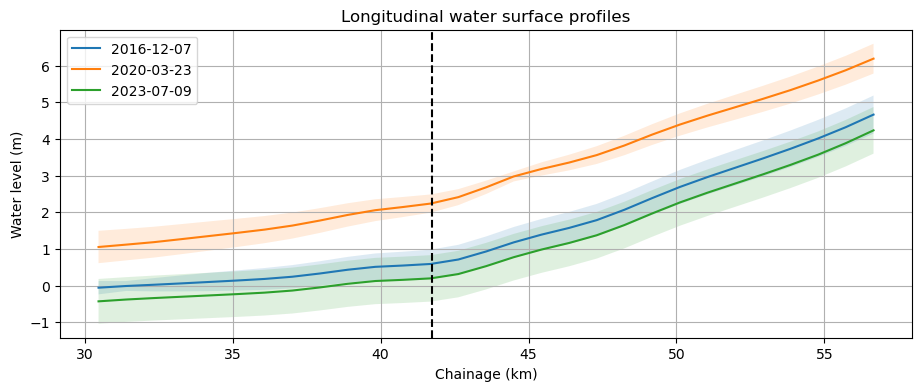

In [5]:
PROFILE_INDICES = [10, 60, 110]
fig, ax = plt.subplots()
for index in PROFILE_INDICES:
    profile = grid.iloc[:, index].to_numpy()
    uncertainty = sdgrid.iloc[:, index].to_numpy()
    ax.plot(chainage, profile, label=f"{time[index]:%Y-%m-%d}")
    ax.fill_between(chainage, profile - uncertainty, profile + uncertainty, alpha=0.15)
ax.axvline(meta.VSchainage / 1000, color="black", linestyle="--")
ax.set(xlabel="Chainage (km)", ylabel="Water level (m)", title="Longitudinal water surface profiles")
ax.legend()
plt.show()

## Geographic position of the reach

Longitude and latitude place each chainage node on the ground. Points are coloured by the mean
water level and the virtual station is marked separately. Geographic-degree axes with a
latitude-corrected aspect ratio preserve the reach's approximate shape at this scale.

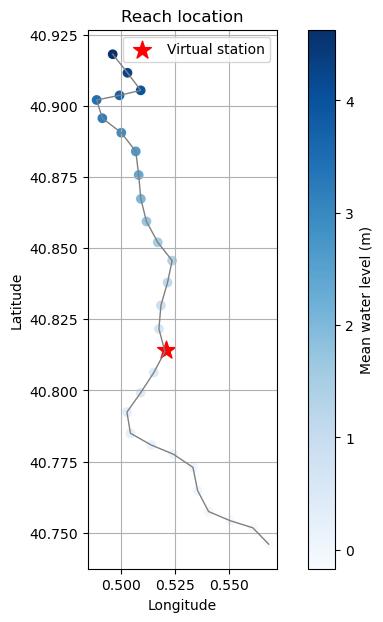

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(by_chainage.lon, by_chainage.lat, color="gray", linewidth=1)
points = ax.scatter(by_chainage.lon, by_chainage.lat, c=grid.mean(axis=1), cmap="Blues")
ax.scatter(meta.VSlon, meta.VSlat, marker="*", s=180, color="red", label="Virtual station")
fig.colorbar(points, ax=ax, label="Mean water level (m)")
ax.set(xlabel="Longitude", ylabel="Latitude", title="Reach location")
ax.set_aspect(1 / np.cos(np.deg2rad(by_chainage.lat.mean())))
ax.legend()
plt.show()